In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv('../Datasets/Cereals.csv')

In [4]:
df

,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
0,100NaturalBran,Q,C,120,3,5,15,2.0,8,8,135,0,3,1.0,1.00,33.983679
1,All-Bran,K,C,70,4,1,260,9.0,7,5,320,25,3,1.0,0.33,59.425505
2,All-BranwithExtraFiber,K,C,50,4,0,140,14.0,8,0,330,25,3,1.0,0.50,93.704912
3,AlmondDelight,R,C,110,2,2,200,1.0,14,8,?,25,3,1.0,0.75,34.384843
4,AppleCinnamonCheerios,G,C,110,2,2,180,1.5,10.5,10,70,25,1,1.0,0.75,29.509541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,Triples,G,C,110,2,1,250,0.0,21,3,60,25,3,1.0,0.75,39.106174
72,Trix,G,C,110,1,1,140,0.0,13,12,25,25,2,1.0,1.00,27.753301
73,WheatChex,R,C,100,3,1,230,3.0,17,3,115,25,1,1.0,0.67,49.787445
74,Wheaties,G,C,100,3,1,200,3.0,17,3,110,25,1,1.0,1.00,51.592193


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76 entries, 0 to 75
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      76 non-null     object 
 1   mfr       76 non-null     object 
 2   type      76 non-null     object 
 3   calories  76 non-null     int64  
 4   protein   76 non-null     int64  
 5   fat       76 non-null     int64  
 6   sodium    76 non-null     int64  
 7   fiber     76 non-null     float64
 8   carbo     76 non-null     object 
 9   sugars    76 non-null     object 
 10  potass    76 non-null     object 
 11  vitamins  76 non-null     int64  
 12  shelf     76 non-null     int64  
 13  weight    76 non-null     float64
 14  cups      76 non-null     float64
 15  rating    76 non-null     float64
dtypes: float64(4), int64(6), object(6)
memory usage: 9.6+ KB


In [6]:
df=df.replace('?',np.nan)

In [7]:
df[['carbo','sugars','potass']]=df[['carbo','sugars','potass']].apply(pd.to_numeric)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76 entries, 0 to 75
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      76 non-null     object 
 1   mfr       76 non-null     object 
 2   type      76 non-null     object 
 3   calories  76 non-null     int64  
 4   protein   76 non-null     int64  
 5   fat       76 non-null     int64  
 6   sodium    76 non-null     int64  
 7   fiber     76 non-null     float64
 8   carbo     75 non-null     float64
 9   sugars    75 non-null     float64
 10  potass    74 non-null     float64
 11  vitamins  76 non-null     int64  
 12  shelf     76 non-null     int64  
 13  weight    76 non-null     float64
 14  cups      76 non-null     float64
 15  rating    76 non-null     float64
dtypes: float64(7), int64(6), object(3)
memory usage: 9.6+ KB


In [9]:
df.isna().sum()

name        0
mfr         0
type        0
calories    0
protein     0
fat         0
sodium      0
fiber       0
carbo       1
sugars      1
potass      2
vitamins    0
shelf       0
weight      0
cups        0
rating      0
dtype: int64

In [10]:
df=df.fillna(df.mean(numeric_only=True))

In [11]:
df.isna().sum()

name        0
mfr         0
type        0
calories    0
protein     0
fat         0
sodium      0
fiber       0
carbo       0
sugars      0
potass      0
vitamins    0
shelf       0
weight      0
cups        0
rating      0
dtype: int64

In [12]:
pd.unique(df['mfr'])

array(['Q', 'K', 'R', 'G', 'P', 'N', 'A'], dtype=object)

In [13]:
df1=df.groupby(['mfr']).value_counts(['name']).reset_index(name='Count')
df1

,mfr,name,Count
0,A,Maypo,1
1,G,AppleCinnamonCheerios,1
2,G,Basic4,1
3,G,Cheerios,1
4,G,CinnamonToastCrunch,1
...,...,...,...
71,R,DoubleChex,1
72,R,MuesliRaisinsDatesAlmonds,1
73,R,MuesliRaisinsPeachesPecans,1
74,R,RiceChex,1


In [14]:
df1=df1.groupby(['mfr'])['Count'].sum().reset_index(name='NoOfCereals')

C:\Users\Samarth\AppData\Local\Temp\ipykernel_9424\93689928.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='mfr',y='NoOfCereals',data=df1,palette='magma')


<Axes: xlabel='mfr', ylabel='NoOfCereals'>

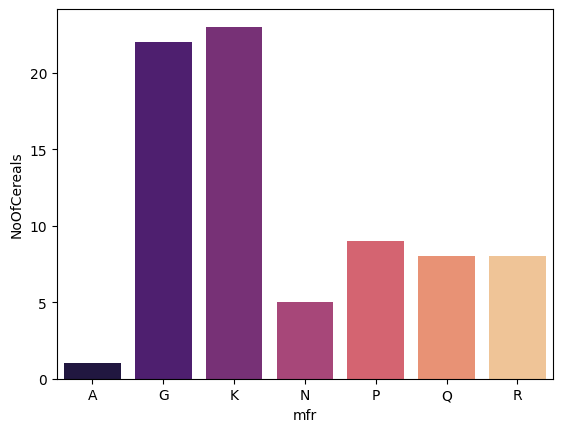

In [15]:
sns.barplot(x='mfr',y='NoOfCereals',data=df1,palette='magma')

In [16]:
print("Best Cereal: ",df[df['rating']==df['rating'].max()]['name'])
print("Worst Cereal: ",df[df['rating']==df['rating'].min()]['name'])

Best Cereal:  2    All-BranwithExtraFiber
Name: name, dtype: object
Worst Cereal:  9    CapnCrunch
Name: name, dtype: object


In [17]:
df1=df.groupby('type')['rating'].mean().reset_index(name='AvgRating')
df1

,type,AvgRating
0,C,41.734838
1,H,56.737708


In [18]:
df2=df[(df['fiber']>df['fiber'].mean()) & (df['sugars']<df['sugars'].mean())]

In [19]:
df2

,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
1,All-Bran,K,C,70,4,1,260,9.0,7.0,5.0,320.0,25,3,1.00,0.33,59.425505
2,All-BranwithExtraFiber,K,C,50,4,0,140,14.0,8.0,0.0,330.0,25,3,1.00,0.50,93.704912
7,BranChex,R,C,90,2,1,200,4.0,15.0,6.0,125.0,25,1,1.00,0.67,49.120253
8,BranFlakes,P,C,90,3,0,210,5.0,13.0,5.0,190.0,25,3,1.00,0.67,53.313813
18,CracklinOatBran,K,C,110,3,3,140,4.0,10.0,7.0,160.0,25,3,1.00,0.50,40.448772
25,FrostedMiniWheats,K,C,100,3,0,0,3.0,14.0,7.0,100.0,25,2,1.00,0.80,58.345141
31,GrapeNutsFlakes,P,C,100,3,1,140,3.0,15.0,5.0,85.0,25,3,1.00,0.88,52.076897
32,Grape-Nuts,P,C,110,3,0,170,3.0,17.0,3.0,90.0,25,3,1.00,0.25,53.371007
33,GreatGrainsPecan,P,C,120,3,3,75,3.0,13.0,4.0,100.0,25,3,1.00,0.33,45.811716
48,Nutri-GrainAlmond-Raisin,K,C,140,3,2,220,3.0,21.0,7.0,130.0,25,3,1.33,0.67,40.692320


In [20]:
df3=df[df['protein']>3]

In [21]:
df3

,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
1,All-Bran,K,C,70,4,1,260,9.0,7.000000,5.00,320.0,25,3,1.0,0.33,59.425505
2,All-BranwithExtraFiber,K,C,50,4,0,140,14.0,8.000000,0.00,330.0,25,3,1.0,0.50,93.704912
10,Cheerios,G,C,110,6,2,290,2.0,17.000000,1.00,105.0,25,1,1.0,1.25,50.764999
40,Life,Q,C,100,4,2,150,2.0,12.000000,6.00,95.0,25,2,1.0,0.67,45.328074
42,Maypo,A,H,100,4,1,0,0.0,16.000000,3.00,95.0,25,2,1.0,1.00,54.850917
43,MuesliRaisinsDatesAlmonds,R,C,150,4,3,95,3.0,16.000000,11.00,170.0,25,3,1.0,1.00,37.136863
44,MuesliRaisinsPeachesPecans,R,C,150,4,3,150,3.0,16.000000,11.00,170.0,25,3,1.0,1.00,34.139765
55,QuakerOatSquares,Q,C,100,4,1,135,2.0,14.000000,6.00,110.0,25,3,1.0,0.50,49.511874
56,QuakerOatmeal,Q,H,100,5,2,0,2.7,14.933333,7.04,110.0,0,1,1.0,0.67,50.828392
66,SpecialK,K,C,110,6,0,230,1.0,16.000000,3.00,55.0,25,1,1.0,1.00,53.131324


In [22]:
df4=df.groupby('shelf')['name']
df4

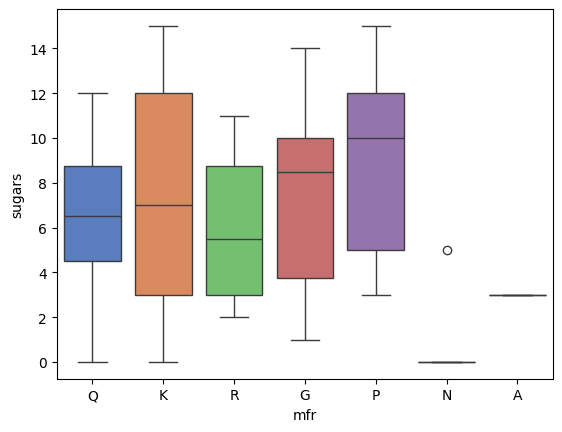

In [51]:
sns.boxplot(x='mfr',y='sugars',data=df,hue='mfr',palette='muted')
plt.show()

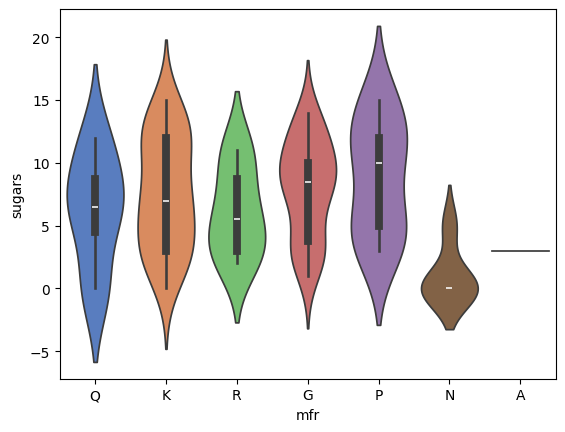

In [50]:
sns.violinplot(x='mfr',y='sugars',data=df,hue='mfr',palette='muted')
plt.show()

In [53]:
df5=df.groupby('mfr')['calories'].mean().reset_index(name='AvgCalories')


In [54]:
df5

,mfr,AvgCalories
0,A,100.000000
1,G,111.363636
2,K,108.695652
3,N,90.000000
4,P,108.888889
5,Q,95.000000
6,R,115.000000


C:\Users\Samarth\AppData\Local\Temp\ipykernel_9424\4119778856.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df5,x='mfr',y='AvgCalories',palette='muted')


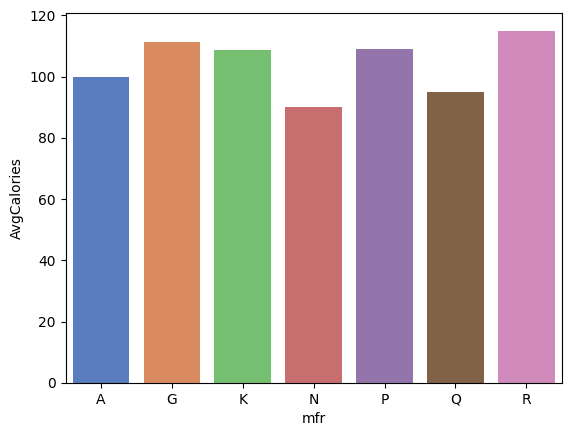

In [55]:
sns.barplot(data=df5,x='mfr',y='AvgCalories',palette='muted')
plt.show()

<Axes: xlabel='mfr', ylabel='calories'>

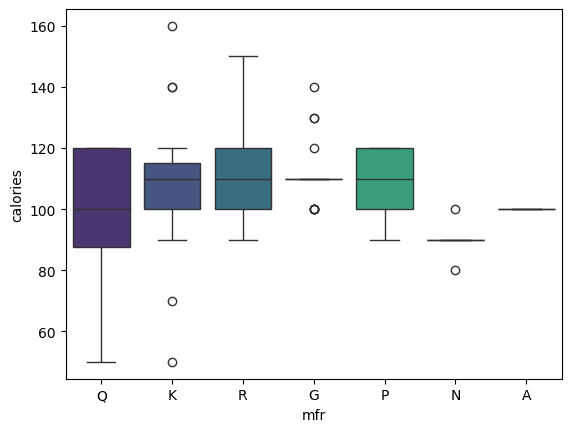

In [27]:
sns.boxplot(x='mfr',y='calories',data=df,hue='mfr',palette='viridis')

C:\Users\Samarth\AppData\Local\Temp\ipykernel_9424\4162362115.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x='sugars',y='calories',data=df,palette='viridis')


<Axes: xlabel='sugars', ylabel='calories'>

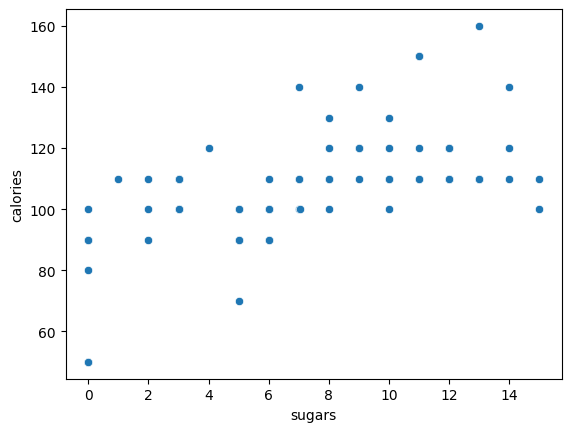

In [28]:
sns.scatterplot(x='sugars',y='calories',data=df,palette='viridis')

In [29]:
df5=df.groupby('shelf')['rating'].mean()

In [30]:
df5

shelf
1    46.145439
2    34.972827
3    44.557662
Name: rating, dtype: float64

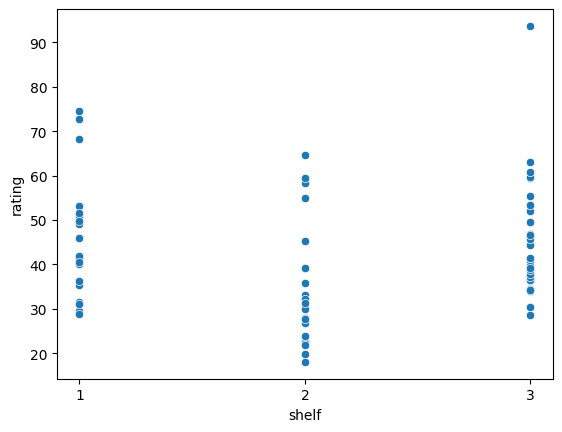

In [31]:
sns.scatterplot(y='rating',x='shelf',data=df)
plt.xticks([1,2,3])
plt.show()

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76 entries, 0 to 75
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      76 non-null     object 
 1   mfr       76 non-null     object 
 2   type      76 non-null     object 
 3   calories  76 non-null     int64  
 4   protein   76 non-null     int64  
 5   fat       76 non-null     int64  
 6   sodium    76 non-null     int64  
 7   fiber     76 non-null     float64
 8   carbo     76 non-null     float64
 9   sugars    76 non-null     float64
 10  potass    76 non-null     float64
 11  vitamins  76 non-null     int64  
 12  shelf     76 non-null     int64  
 13  weight    76 non-null     float64
 14  cups      76 non-null     float64
 15  rating    76 non-null     float64
dtypes: float64(7), int64(6), object(3)
memory usage: 9.6+ KB


In [33]:
df['avgNutrition']=df[['calories','fat','protein']].mean(axis=1)

In [34]:
df

,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating,avgNutrition
0,100NaturalBran,Q,C,120,3,5,15,2.0,8.0,8.0,135.000000,0,3,1.0,1.00,33.983679,42.666667
1,All-Bran,K,C,70,4,1,260,9.0,7.0,5.0,320.000000,25,3,1.0,0.33,59.425505,25.000000
2,All-BranwithExtraFiber,K,C,50,4,0,140,14.0,8.0,0.0,330.000000,25,3,1.0,0.50,93.704912,18.000000
3,AlmondDelight,R,C,110,2,2,200,1.0,14.0,8.0,96.216216,25,3,1.0,0.75,34.384843,38.000000
4,AppleCinnamonCheerios,G,C,110,2,2,180,1.5,10.5,10.0,70.000000,25,1,1.0,0.75,29.509541,38.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,Triples,G,C,110,2,1,250,0.0,21.0,3.0,60.000000,25,3,1.0,0.75,39.106174,37.666667
72,Trix,G,C,110,1,1,140,0.0,13.0,12.0,25.000000,25,2,1.0,1.00,27.753301,37.333333
73,WheatChex,R,C,100,3,1,230,3.0,17.0,3.0,115.000000,25,1,1.0,0.67,49.787445,34.666667
74,Wheaties,G,C,100,3,1,200,3.0,17.0,3.0,110.000000,25,1,1.0,1.00,51.592193,34.666667


In [35]:
df5=df['shelf'].value_counts().reset_index(name='count')

In [36]:
df5

,shelf,count
0,3,35
1,2,21
2,1,20


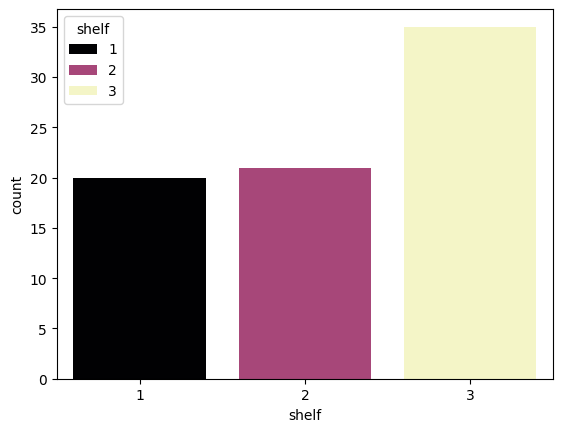

In [37]:
sns.barplot(data=df5,x='shelf',y='count',hue='shelf',palette='magma')
plt.show()

In [38]:
df['rating'].mean()

np.float64(42.32705672368421)

In [39]:
df['ratingCategory']=df['rating'].apply(lambda x: "high" if x>df['rating'].mean() else "low")

In [40]:
df

,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating,avgNutrition,ratingCategory
0,100NaturalBran,Q,C,120,3,5,15,2.0,8.0,8.0,135.000000,0,3,1.0,1.00,33.983679,42.666667,low
1,All-Bran,K,C,70,4,1,260,9.0,7.0,5.0,320.000000,25,3,1.0,0.33,59.425505,25.000000,high
2,All-BranwithExtraFiber,K,C,50,4,0,140,14.0,8.0,0.0,330.000000,25,3,1.0,0.50,93.704912,18.000000,high
3,AlmondDelight,R,C,110,2,2,200,1.0,14.0,8.0,96.216216,25,3,1.0,0.75,34.384843,38.000000,low
4,AppleCinnamonCheerios,G,C,110,2,2,180,1.5,10.5,10.0,70.000000,25,1,1.0,0.75,29.509541,38.000000,low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,Triples,G,C,110,2,1,250,0.0,21.0,3.0,60.000000,25,3,1.0,0.75,39.106174,37.666667,low
72,Trix,G,C,110,1,1,140,0.0,13.0,12.0,25.000000,25,2,1.0,1.00,27.753301,37.333333,low
73,WheatChex,R,C,100,3,1,230,3.0,17.0,3.0,115.000000,25,1,1.0,0.67,49.787445,34.666667,high
74,Wheaties,G,C,100,3,1,200,3.0,17.0,3.0,110.000000,25,1,1.0,1.00,51.592193,34.666667,high


In [41]:
df1=df.groupby('ratingCategory')['sugars'].mean()

In [42]:
df1

ratingCategory
high    3.208276
low     9.404255
Name: sugars, dtype: float64

In [43]:
df2=df.groupby('ratingCategory')[['fiber','sugars']].mean()

In [44]:
df2

,fiber,sugars
ratingCategory,,
high,2.955172,3.208276
low,1.489362,9.404255


In [45]:
print(df['fiber'].mean())
print(df['sugars'].mean())

2.0486842105263157
7.039999999999999


In [46]:
df['BodyImpact']=df.apply(lambda x: "healthy" if (x['fiber']>2.048) & (x['sugars']<7.03) else "UnHealthy",axis=1)

In [47]:
df1=df.groupby(['BodyImpact','ratingCategory']).size().reset_index(name='count')

In [48]:
df1

,BodyImpact,ratingCategory,count
0,UnHealthy,high,13
1,UnHealthy,low,45
2,healthy,high,16
3,healthy,low,2


In [49]:
print(df.groupby('ratingCategory')['rating'].mean())

ratingCategory
high    56.305493
low     33.702064
Name: rating, dtype: float64
